# Week 6 — Cross-Architecture Replication on Llama-3.2-3B (No QK-Norm)

Weeks 1–5b established five core findings on **Qwen3-1.7B** (`28` layers, `8` KV heads, `head_dim = 128`, with per-head `k_norm`).
This notebook replicates the complete winning suite on a second model family — **`Llama-3.2-3B`** (`unsloth/Llama-3.2-3B`, unquantized weights, ungated mirror):

- **Exact 1-to-1 KV geometry** (`28` layers, `8` KV heads, `head_dim = 128`, `D_KV = 1024`), so depth quartiles (`0–6`, `7–13`, `14–20`, `21–27`) and `layers 3–27` align directly with Qwen3-1.7B.
- **Architectural contrast:** Llama-3.2 has **no QK-Norm (`k_norm`)**, a different tokenizer (128k Tiktoken BPE), and a different pretraining mix.

### Five compact experiments in one notebook
1. **Part 1 — Spectral & position-0 sink diagnostics (~30 s):** per-head `NER`/`r90/r95/r99`, within-layer Spearman agreement, per-position norms (`t = 0..50`), and cosine distortion of `K[0]` without `k_norm`.
2. **Part 2 — Three-way position-0 test on `K` (late layers):** `skip1_proj_all` vs `gram_all_proj_all` (standard SVD) vs `protect_pos0`. Directly tests whether standard SVD breaks `K[0]` *even without `k_norm`*.
3. **Part 3 — Depth-band sweep (`early`, `mid1`, `mid2`, `late`) for `K` vs `V` (`joint`, `r = 0.25`, `protect_pos0 = True`):** checks if `K` stays language-agnostic across depth while `V` carries the cross-lingual bias.
4. **Part 4 — Full-model 4× `K+V` compression (`layers 3–27`, `joint`, `r = 0.25`, `protect_pos0 = True`):** tests whether English-only calibration breaks non-English languages and whether `mix_5k` (`w = 0.10`, ~5k tokens) + `multi` rescue full-model compression.
5. **Part 5 — Parallel-corpus control on FLORES-200 (`V`, late layers, `r = 0.25`, `protect_pos0 = True`):** `flores_to_flores` (`head` & `joint`) + `wiki_to_flores` (`joint`) on exact translated sentences (`eng_Latn`, `spa_Latn`, `fin_Latn`, `quy_Latn`).

**Kaggle settings.** GPU T4 ×1, Internet On. Run once with `SMOKE_TEST = True` on CPU first.
Expected runtime on one T4: ~55–62 min with `Llama-3.2-3B` (~25 min with `QUICK = True` or `unsloth/Llama-3.2-1B`).

In [1]:
import os

SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"   # True for <30s CPU dry run
QUICK = False                                           # True: ~25 min on T4

# Ungated unquantized mirror of Meta Llama-3.2-3B (switch to "unsloth/Llama-3.2-1B" for 2x speed,
# or "meta-llama/Llama-3.2-3B" if HF_TOKEN is configured with Meta license access)
MODEL_ID = "unsloth/Llama-3.2-3B"
LANGS = ["en", "es", "fi", "qu"]
FLORES_CODES = {
    "en": "eng_Latn",
    "es": "spa_Latn",
    "fi": "fin_Latn",
    "qu": "quy_Latn",
}
WIKI_SNAPSHOT = "20231101"

SEQ_LEN = 512
CALIB_TOKENS = 150_000
EVAL_TOKENS = 60_000
LOW_BUDGET_WINDOWS = 10         # 10 * 512 = 5,120 tokens (~5k low-resource recipe)
MIX_WEIGHT = 0.10
MAX_TOKENS_PER_ARTICLE = 2048
MIN_CHARS_PER_ARTICLE = 500
MIN_FILL = 0.5

CALIB_BATCH = 4                 # T4-safe for 3B (~8.5 GB peak VRAM)
EVAL_BATCH = 2                  # Keeps fp32 logits small on 16 GB T4
R_MAIN = 0.25
N_BOOT = 2000
SEED = 0

OUT_DIR = "/kaggle/working/kv_rank_week6_llama32" if os.path.isdir("/kaggle/working") else "./kv_rank_week6_llama32"
os.makedirs(OUT_DIR, exist_ok=True)

if SMOKE_TEST:
    LANGS = ["aa", "bb", "cc"]
    FLORES_CODES = {"aa": "aa", "bb": "bb", "cc": "cc"}
    SEQ_LEN = 64
    CALIB_TOKENS = 64 * 24
    EVAL_TOKENS = 64 * 12
    LOW_BUDGET_WINDOWS = 4
    CALIB_BATCH, EVAL_BATCH, N_BOOT = 8, 4, 200

print(f"MODEL_ID={MODEL_ID} | SMOKE_TEST={SMOKE_TEST} | QUICK={QUICK} | output -> {OUT_DIR}")

MODEL_ID=unsloth/Llama-3.2-3B | SMOKE_TEST=False | QUICK=False | output -> /kaggle/working/kv_rank_week6_llama32


In [2]:
import itertools, json, math, tarfile, time, urllib.request, zlib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch:", torch.__version__)

device: cuda | torch: 2.11.0+cu130


## 1. Model

In [3]:
from transformers import AutoModelForCausalLM, AutoTokenizer

if SMOKE_TEST:
    from transformers import LlamaConfig, LlamaForCausalLM
    model = LlamaForCausalLM(LlamaConfig(
        vocab_size=1000, hidden_size=64, intermediate_size=128,
        num_hidden_layers=4, num_attention_heads=4,
        num_key_value_heads=2, max_position_embeddings=256,
    ))
    tokenizer = None
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    half = torch.float16 if device == "cuda" else torch.float32
    try:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=half)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=half)

model.to(device).eval()

cfg = model.config
N_LAYERS = cfg.num_hidden_layers
N_KV = getattr(cfg, "num_key_value_heads", None) or cfg.num_attention_heads
HEAD_DIM = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
D_KV = N_KV * HEAD_DIM

PROJ = {"K": [], "V": []}
has_knorm = False
for name, mod in model.named_modules():
    if name.endswith("self_attn.k_proj"):
        PROJ["K"].append(mod)
    elif name.endswith("self_attn.v_proj"):
        PROJ["V"].append(mod)
    elif name.endswith("self_attn.k_norm"):
        has_knorm = True

assert len(PROJ["K"]) == len(PROJ["V"]) == N_LAYERS
q = max(1, N_LAYERS // 4)
BANDS = {
    "early": list(range(0, q)),
    "mid1":  list(range(q, 2 * q)),
    "mid2":  list(range(2 * q, 3 * q)),
    "late":  list(range(3 * q, N_LAYERS)),
}
LATE = BANDS["late"]
NO_SINK_LAYERS = list(range(min(3, N_LAYERS - 1), N_LAYERS))   # layers 3..27 for 28-layer model

print(f"arch={cfg.model_type} layers={N_LAYERS} q_heads={cfg.num_attention_heads} kv_heads={N_KV} "
      f"head_dim={HEAD_DIM} kv_width={D_KV} has_k_norm={has_knorm}")
print("bands:", {k: f"{v[0]}–{v[-1]}" for k, v in BANDS.items()}, f"| no_sink: {NO_SINK_LAYERS[0]}–{NO_SINK_LAYERS[-1]}")

config.json:   0%|          | 0.00/890 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.6k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/459 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/230 [00:00<?, ?B/s]

arch=llama layers=28 q_heads=24 kv_heads=8 head_dim=128 kv_width=1024 has_k_norm=False
bands: {'early': '0–6', 'mid1': '7–13', 'mid2': '14–20', 'late': '21–27'} | no_sink: 3–27


## 2. Data: Wikipedia splits + FLORES-200 parallel corpus

In [4]:
def wiki_splits(lang):
    from datasets import load_dataset
    ds = load_dataset("wikimedia/wikipedia", f"{WIKI_SNAPSHOT}.{lang}", split="train", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=2000)
    need = {"calib": CALIB_TOKENS // SEQ_LEN, "eval": EVAL_TOKENS // SEQ_LEN}
    win = {"calib": [], "eval": []}
    for row in ds:
        if len(row["text"]) < MIN_CHARS_PER_ARTICLE:
            continue
        split = "calib" if zlib.crc32(str(row["id"]).encode()) % 2 == 0 else "eval"
        if len(win[split]) >= need[split]:
            if all(len(win[s]) >= need[s] for s in win):
                break
            continue
        ids = tokenizer(row["text"], add_special_tokens=False)["input_ids"][:MAX_TOKENS_PER_ARTICLE]
        for i in range(0, len(ids) - SEQ_LEN + 1, SEQ_LEN):
            if len(win[split]) < need[split]:
                win[split].append(ids[i:i + SEQ_LEN])
    for s in win:
        if len(win[s]) < MIN_FILL * need[s]:
            raise RuntimeError(f"{lang}/{s}: only {len(win[s])}/{need[s]} windows")
    return {s: torch.tensor(w, dtype=torch.long) for s, w in win.items()}


FLORES_CACHE = os.path.join(OUT_DIR, "_flores200")


def _download_flores_tarball():
    dev_dir = os.path.join(FLORES_CACHE, "flores200_dataset", "dev")
    if os.path.isdir(dev_dir):
        return os.path.join(FLORES_CACHE, "flores200_dataset")
    os.makedirs(FLORES_CACHE, exist_ok=True)
    tgz = os.path.join(FLORES_CACHE, "flores200_dataset.tar.gz")
    for url in (
        "https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz",
        "https://tinyurl.com/flores200dataset",
    ):
        try:
            print(f"Downloading FLORES-200 from {url} ...")
            urllib.request.urlretrieve(url, tgz)
            with tarfile.open(tgz, "r:gz") as tf:
                try:
                    tf.extractall(FLORES_CACHE, filter="data")
                except TypeError:
                    tf.extractall(FLORES_CACHE)
            if os.path.isdir(dev_dir):
                return os.path.join(FLORES_CACHE, "flores200_dataset")
        except Exception as e:
            print(f"  tarball attempt failed ({url}): {e}")
    return None


def _extract_text_column(ds):
    for col in ("sentence", "text", "target", "source"):
        if col in ds.column_names:
            return [str(x).strip() for x in ds[col]]
    raise KeyError(f"Could not find text column in {ds.column_names}")


def load_flores_sentences(code, split):
    root = _download_flores_tarball()
    if root is not None:
        p = os.path.join(root, split, f"{code}.{split}")
        if os.path.isfile(p):
            with open(p, encoding="utf-8") as fh:
                return [line.strip() for line in fh if line.strip()]
    from datasets import load_dataset
    sp = "validation" if split == "dev" else "test"
    ds = load_dataset("tomasmajercik/flores-parquet", name=code, split=sp)
    return _extract_text_column(ds)


def pack_sentences(sentences):
    sep = tokenizer("\n", add_special_tokens=False)["input_ids"]
    buf, n_toks = [], 0
    for s in sentences:
        ids = tokenizer(s, add_special_tokens=False)["input_ids"]
        n_toks += len(ids)
        buf.extend(ids)
        buf.extend(sep)
    n_win = len(buf) // SEQ_LEN
    arr = torch.tensor(buf[:n_win * SEQ_LEN], dtype=torch.long).view(n_win, SEQ_LEN)
    return arr, n_toks / max(1, len(sentences))


def smoke_all_splits(lang):
    lo = {"aa": 0, "bb": 300, "cc": 600}[lang]
    g = torch.Generator().manual_seed(SEED + lo)
    mk = lambda n: torch.randint(lo, lo + 300, (n // SEQ_LEN, SEQ_LEN), generator=g)
    return {"calib": mk(CALIB_TOKENS), "eval": mk(EVAL_TOKENS)}, {"dev": mk(CALIB_TOKENS // 2), "devtest": mk(EVAL_TOKENS)}, 25.0


wiki_data, flores_data, fertility = {}, {}, {}
for lang in LANGS:
    t0 = time.time()
    if SMOKE_TEST:
        wiki_data[lang], flores_data[lang], fertility[lang] = smoke_all_splits(lang)
    else:
        wiki_data[lang] = wiki_splits(lang)
        dev_win, f_dev = pack_sentences(load_flores_sentences(FLORES_CODES[lang], "dev"))
        test_win, f_test = pack_sentences(load_flores_sentences(FLORES_CODES[lang], "devtest"))
        flores_data[lang] = {"dev": dev_win, "devtest": test_win}
        fertility[lang] = round((f_dev + f_test) / 2, 2)
    print(
        f"{lang}: wiki {tuple(wiki_data[lang]['calib'].shape)}/{tuple(wiki_data[lang]['eval'].shape)} | "
        f"flores {tuple(flores_data[lang]['dev'].shape)}/{tuple(flores_data[lang]['devtest'].shape)} "
        f"(~{fertility[lang]} tok/sent, {time.time()-t0:.0f}s)"
    )

min_fdev = min(len(flores_data[l]["dev"]) for l in LANGS)
for lang in LANGS:
    flores_data[lang]["dev_eq"] = flores_data[lang]["dev"][:min_fdev]
print(f"FLORES dev equalized calibration budget: {min_fdev} windows ({min_fdev * SEQ_LEN:,} tokens/lang)")

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/41 [00:00<?, ?it/s]

en: wiki (292, 512)/(117, 512) | flores (52, 512)/(55, 512) (~26.36 tok/sent, 8s)
es: wiki (292, 512)/(117, 512) | flores (79, 512)/(83, 512) (~40.64 tok/sent, 5s)
fi: wiki (292, 512)/(117, 512) | flores (101, 512)/(107, 512) (~52.32 tok/sent, 4s)
qu: wiki (292, 512)/(117, 512) | flores (105, 512)/(111, 512) (~54.42 tok/sent, 4s)
FLORES dev equalized calibration budget: 52 windows (26,624 tokens/lang)


In [5]:
class MultiGramCollector:
    """Single-pass collector for skip=1 (K, V) and optionally skip=0 (K, V)."""
    def __init__(self, collect_all=True):
        self.collect_all = collect_all
        self.g1 = {k: torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device) for k in ("K", "V")}
        self.n1 = 0
        if collect_all:
            self.g0 = {k: torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device) for k in ("K", "V")}
            self.n0 = 0
        self.handles = [m.register_forward_hook(self._hook(k, l)) for k in ("K", "V") for l, m in enumerate(PROJ[k])]

    def _hook(self, kind, layer):
        def fn(mod, inp, out):
            x1 = out[:, 1:, :].reshape(-1, D_KV).float()
            self.g1[kind][layer] += (x1.T @ x1).double()
            if kind == "K" and layer == 0:
                self.n1 += x1.shape[0]
            if self.collect_all:
                x0 = out.reshape(-1, D_KV).float()
                self.g0[kind][layer] += (x0.T @ x0).double()
                if kind == "K" and layer == 0:
                    self.n0 += x0.shape[0]
        return fn

    def snap1(self):
        return {k: (g / self.n1).cpu().numpy() for k, g in self.g1.items()}

    def finish(self):
        for h in self.handles:
            h.remove()
        res = {"skip1": self.snap1()}
        if self.collect_all:
            res["all"] = {k: (g / self.n0).cpu().numpy() for k, g in self.g0.items()}
        return res


@torch.no_grad()
def forward_collect(windows, batch, snap_at=None, collect_all=False):
    c = MultiGramCollector(collect_all=collect_all)
    snaps = {}
    if snap_at is not None and snap_at < len(windows):
        for i in range(0, snap_at, batch):
            model(input_ids=windows[i:min(i + batch, snap_at)].to(device), use_cache=False)
        snaps[snap_at] = c.snap1()
        for i in range(snap_at, len(windows), batch):
            model(input_ids=windows[i:i + batch].to(device), use_cache=False)
    else:
        for i in range(0, len(windows), batch):
            model(input_ids=windows[i:i + batch].to(device), use_cache=False)
        if snap_at is not None:
            snaps[snap_at] = c.snap1()
    return c.finish(), snaps


@torch.no_grad()
def window_nll(windows, batch):
    out = []
    for i in range(0, len(windows), batch):
        ids = windows[i:i + batch].to(device)
        logits = model(input_ids=ids, use_cache=False).logits[:, :-1].float()
        nll = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), ids[:, 1:].reshape(-1), reduction="none")
        out.append(nll.view(ids.shape[0], -1).mean(1).cpu())
        del logits, nll
    return torch.cat(out).numpy().astype(np.float64)


gram_w_cal, gram_w_all, gram_w_5k, gram_w_eval, base_w_nll = {}, {}, {}, {}, {}
gram_f_cal, gram_f_5k, gram_f_eval, base_f_nll = {}, {}, {}, {}

for lang in LANGS:
    t0 = time.time()
    out_wc, snaps_w = forward_collect(wiki_data[lang]["calib"], CALIB_BATCH, snap_at=LOW_BUDGET_WINDOWS, collect_all=True)
    gram_w_cal[lang] = out_wc["skip1"]
    gram_w_all[lang] = out_wc["all"]
    gram_w_5k[lang] = snaps_w[LOW_BUDGET_WINDOWS]

    c = MultiGramCollector(collect_all=False)
    base_w_nll[lang] = window_nll(wiki_data[lang]["eval"], EVAL_BATCH)
    gram_w_eval[lang] = c.finish()["skip1"]

    out_fc, snaps_f = forward_collect(flores_data[lang]["dev_eq"], CALIB_BATCH, snap_at=LOW_BUDGET_WINDOWS, collect_all=False)
    gram_f_cal[lang] = out_fc["skip1"]
    gram_f_5k[lang] = snaps_f[LOW_BUDGET_WINDOWS]

    c = MultiGramCollector(collect_all=False)
    base_f_nll[lang] = window_nll(flores_data[lang]["devtest"], EVAL_BATCH)
    gram_f_eval[lang] = c.finish()["skip1"]

    if device == "cuda":
        torch.cuda.empty_cache()
    print(f"{lang}: wiki ppl={math.exp(base_w_nll[lang].mean()):.2f} | "
          f"flores ppl={math.exp(base_f_nll[lang].mean()):.2f} ({time.time()-t0:.0f}s)")

with open(os.path.join(OUT_DIR, "baseline_ppl.json"), "w") as fh:
    json.dump({
        "model_id": MODEL_ID,
        "wiki": {l: math.exp(v.mean()) for l, v in base_w_nll.items()},
        "flores": {l: math.exp(v.mean()) for l, v in base_f_nll.items()},
        "flores_tok_per_sent": fertility,
    }, fh, indent=2)

en: wiki ppl=9.35 | flores ppl=19.42 (144s)
es: wiki ppl=7.22 | flores ppl=11.82 (158s)
fi: wiki ppl=5.40 | flores ppl=9.42 (165s)
qu: wiki ppl=10.16 | flores ppl=56.64 (166s)


In [6]:
def top_basis(G, r):
    lam, U = np.linalg.eigh(G)
    return U[:, ::-1][:, :r]


def blocks(G):
    return [G[h * HEAD_DIM:(h + 1) * HEAD_DIM, h * HEAD_DIM:(h + 1) * HEAD_DIM] for h in range(N_KV)]


def make_projector(G_layer, scope, f):
    if scope == "head":
        r = max(1, round(f * HEAD_DIM))
        P = np.stack([(lambda U: U @ U.T)(top_basis(B, r)) for B in blocks(G_layer)])
    else:
        r = max(1, round(f * D_KV))
        U = top_basis(G_layer, r)
        P = U @ U.T
    return torch.tensor(P, dtype=next(model.parameters()).dtype, device=device)


def project_hook(P, scope, protect_first=1):
    def fn(mod, inp, out):
        tail = out[:, protect_first:, :] if protect_first > 0 else out
        if scope == "head":
            B, T, _ = tail.shape
            proj = torch.einsum("btnd,nde->btne", tail.reshape(B, T, N_KV, HEAD_DIM), P).reshape(B, T, D_KV)
        else:
            proj = tail @ P
        if protect_first > 0:
            return torch.cat([out[:, :protect_first, :], proj], dim=1)
        return proj
    return fn


def run_config(eval_windows, gram_src, kind, scope, f, layers, protect_first=1):
    sub_kinds = ("K", "V") if kind == "KV" else (kind,)
    handles = [
        PROJ[sk][l].register_forward_hook(
            project_hook(make_projector(gram_src[sk][l], scope, f), scope, protect_first=protect_first)
        )
        for sk in sub_kinds for l in layers
    ]
    try:
        return window_nll(eval_windows, EVAL_BATCH)
    finally:
        for h in handles:
            h.remove()


rng = np.random.default_rng(SEED)


def paired(a, b):
    d = a - b
    boots = d[rng.integers(0, len(d), size=(N_BOOT, len(d)))].mean(1)
    return float(d.mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


def avg_grams(glist):
    return {k: sum(g[k] for g in glist) / len(glist) for k in ("K", "V")}


def mix_grams(g_other, g_tgt, w):
    return {k: (1.0 - w) * g_other[k] + w * g_tgt[k] for k in ("K", "V")}


def make_src_gram(corpus, src, tgt):
    g_full = gram_w_cal if corpus == "wiki" else gram_f_cal
    g_5k = gram_w_5k if corpus == "wiki" else gram_f_5k
    g_eval = gram_w_eval if corpus == "wiki" else gram_f_eval
    if src == "oracle":    return g_eval[tgt]
    if src == "matched":   return g_full[tgt]
    if src == "multi":     return avg_grams([g_full[l] for l in LANGS])
    if src == "multi_loo": return avg_grams([g_full[l] for l in LANGS if l != tgt])
    if src == "mix_5k":
        return mix_grams(avg_grams([g_full[l] for l in LANGS if l != tgt]), g_5k[tgt], MIX_WEIGHT)
    return g_full[src]


en_code, qu_code = LANGS[0], LANGS[-1]

## 3. Part 1 — Spectral & Position-0 Sink Diagnostics on Llama-3.2 (fast, ~20 s)

Checks:
1. Per-head `NER` and `r90/r95/r99` across `en`, `es`, `fi`, `qu` (plus within-layer Spearman head agreement).
2. Per-position norms (`t = 0..50`) and per-layer `||pos 0|| / ||pos >= 1||` ratio (does Llama-3.2 without QK-Norm also have the layer 0–2 spike and low-norm `V[0]` sink?).
3. Direction distortion (cosine similarity of `K[0]` vs `K[pos >= 1]`) under `head r=0.25` and `joint r=0.25`.

In [7]:
def spectrum_metrics(G):
    lam = np.clip(np.linalg.eigvalsh(G)[::-1], 0.0, None)
    s = np.sqrt(lam)
    p = s / s.sum(); p = p[p > 0]
    erank = float(np.exp(-(p * np.log(p)).sum()))
    en = np.cumsum(lam) / lam.sum()
    d = len(lam)
    return dict(ner=erank / d,
                r90=float((np.searchsorted(en, 0.90) + 1) / d),
                r95=float((np.searchsorted(en, 0.95) + 1) / d),
                r99=float((np.searchsorted(en, 0.99) + 1) / d))


spec_rows = []
for lang, kind, l in itertools.product(LANGS, ("K", "V"), range(N_LAYERS)):
    G = gram_w_cal[lang][kind][l]
    for h, B in enumerate(blocks(G)):
        spec_rows.append(dict(lang=lang, kind=kind, layer=l, head=h, **spectrum_metrics(B)))
spec_df = pd.DataFrame(spec_rows)
spec_df.to_csv(os.path.join(OUT_DIR, "part1_spectra.csv"), index=False)
print("=== Mean per-head spectral compressibility (Llama-3.2) ===")
display(spec_df.groupby(["lang", "kind"])[["ner", "r90", "r95", "r99"]].mean().round(3))

# Within-layer Spearman agreement
def spearman(a, b):
    return float(pd.Series(a).rank().corr(pd.Series(b).rank()))

ag = []
for kind in ("K", "V"):
    maps = {l: spec_df[(spec_df.lang == l) & (spec_df.kind == kind)].pivot(index="layer", columns="head", values="ner").values
            for l in LANGS}
    for a, b in itertools.combinations(LANGS, 2):
        wa = maps[a] - maps[a].mean(axis=1, keepdims=True)
        wb = maps[b] - maps[b].mean(axis=1, keepdims=True)
        ag.append(dict(kind=kind, pair=f"{a}-{b}", spearman_within_layer=spearman(wa.ravel(), wb.ravel())))
print("\n=== Cross-language head agreement (within-layer Spearman) ===")
display(pd.DataFrame(ag).pivot(index="pair", columns="kind", values="spearman_within_layer").round(3))

# Per-layer pos-0 norm ratio + per-position norms + K cosine distortion
POS_CHECK = [p for p in [0, 1, 2, 3, 4, 5, 10, 20, 50] if p < SEQ_LEN]

@torch.no_grad()
def diag_pos0_llama(lang, n_win=12):
    sub = wiki_data[lang]["eval"][:min(n_win, len(wiki_data[lang]["eval"]))]
    projs = {l: {"head_r25": make_projector(gram_w_cal[lang]["K"][l], "head", 0.25),
                 "joint_r25": make_projector(gram_w_cal[lang]["K"][l], "joint", 0.25)} for l in LATE}
    pos_norms = {k: torch.zeros(N_LAYERS, len(POS_CHECK), dtype=torch.float64, device=device) for k in ("K", "V")}
    norm_p0 = {k: torch.zeros(N_LAYERS, dtype=torch.float64, device=device) for k in ("K", "V")}
    norm_rest = {k: torch.zeros(N_LAYERS, dtype=torch.float64, device=device) for k in ("K", "V")}
    cos_acc = {(l, tag, part): [0.0, 0] for l in LATE for tag in ("head_r25", "joint_r25") for part in ("pos0", "rest")}
    n_seq, n_rest = [0], [0]

    def mk(kind, l):
        def fn(mod, inp, out):
            xf = out.float()
            for pi, p in enumerate(POS_CHECK):
                pos_norms[kind][l, pi] += xf[:, p, :].norm(dim=-1).double().sum()
            norm_p0[kind][l] += xf[:, 0, :].norm(dim=-1).double().sum()
            norm_rest[kind][l] += xf[:, 1:, :].norm(dim=-1).double().sum()
            if kind == "K" and l == 0:
                n_seq[0] += xf.shape[0]
                n_rest[0] += xf[:, 1:, :].shape[0] * xf[:, 1:, :].shape[1]
            if kind == "K" and l in LATE:
                B, T, _ = xf.shape
                raw_4d = out.reshape(B, T, N_KV, HEAD_DIM)
                for tag, P in projs[l].items():
                    pr = torch.einsum("btnd,nde->btne", raw_4d, P) if tag.startswith("head") else (out @ P).reshape(B, T, N_KV, HEAD_DIM)
                    cs = F.cosine_similarity(raw_4d.float(), pr.float(), dim=-1)
                    cos_acc[(l, tag, "pos0")][0] += cs[:, 0, :].sum().item(); cos_acc[(l, tag, "pos0")][1] += cs[:, 0, :].numel()
                    cos_acc[(l, tag, "rest")][0] += cs[:, 1:, :].sum().item(); cos_acc[(l, tag, "rest")][1] += cs[:, 1:, :].numel()
        return fn

    hs = [m.register_forward_hook(mk(k, l)) for k in ("K", "V") for l, m in enumerate(PROJ[k])]
    try:
        for i in range(0, len(sub), EVAL_BATCH):
            model(input_ids=sub[i:i + EVAL_BATCH].to(device), use_cache=False)
    finally:
        for h in hs:
            h.remove()

    layer_rows = []
    for k in ("K", "V"):
        for l in range(N_LAYERS):
            r0 = float(norm_p0[k][l] / n_seq[0])
            rr = float(norm_rest[k][l] / n_rest[0])
            layer_rows.append(dict(lang=lang, kind=k, layer=l, norm_ratio=r0 / (rr + 1e-12)))
    pos_rows = [dict(lang=lang, kind=k, layer=l, band="late" if l in LATE else "other",
                     pos=p, norm=float(pos_norms[k][l, pi] / n_seq[0]))
                for k in ("K", "V") for l in range(N_LAYERS) for pi, p in enumerate(POS_CHECK)]
    cos_rows = [dict(lang=lang, layer=l, projector=tag, part=part, cos_sim=s / max(1, c))
                for (l, tag, part), (s, c) in cos_acc.items()]
    return pd.DataFrame(layer_rows), pd.DataFrame(pos_rows), pd.DataFrame(cos_rows)


l_df, p_df, c_df = diag_pos0_llama(en_code)
l_df.to_csv(os.path.join(OUT_DIR, "part1_pos0_layer_ratios.csv"), index=False)
c_df.to_csv(os.path.join(OUT_DIR, "part1_k_cosine.csv"), index=False)
print("\n=== K cosine similarity (late layers, no k_norm): pos 0 vs pos >= 1 ===")
display(c_df.groupby(["projector", "part"]).cos_sim.mean().unstack().round(4))

=== Mean per-head spectral compressibility (Llama-3.2) ===


ner    r90    r95    r99
lang kind                            
en   K     0.587  0.183  0.347  0.660
     V     0.931  0.751  0.863  0.970
es   K     0.580  0.176  0.334  0.650
     V     0.919  0.729  0.849  0.967
fi   K     0.561  0.152  0.302  0.629
     V     0.899  0.689  0.823  0.959
qu   K     0.548  0.136  0.282  0.619
     V     0.893  0.681  0.819  0.959


=== Cross-language head agreement (within-layer Spearman) ===


kind,K,V
pair,,
en-es,0.985,0.895
en-fi,0.956,0.781
en-qu,0.955,0.876
es-fi,0.985,0.920
es-qu,0.964,0.895
fi-qu,0.972,0.900



=== K cosine similarity (late layers, no k_norm): pos 0 vs pos >= 1 ===


part,pos0,rest
projector,,
head_r25,0.7515,0.9571
joint_r25,0.8440,0.9848


## 4. Part 2 — Position-0 Treatment on `K` Without QK-Norm (Late Layers)

Direct test of the architectural question from Week 5b: on **Llama-3.2** (which has **no `k_norm`**), does standard unweighted full-sequence SVD (`gram_all_proj_all`, `SKIP_FIRST_TOKENS = 0`) *still* break `K[0]`, and does `protect_pos0` rescue it?

In [8]:
p2_targets = LANGS if SMOKE_TEST else ([en_code, qu_code] if QUICK else [en_code, "fi", qu_code])
p2_treats = [
    ("skip1_proj_all",    "skip1", 0),
    ("gram_all_proj_all", "all",   0),
    ("protect_pos0",      "skip1", 1),
]
cfgs2 = [(tr, gt, pf, sc, tgt)
         for tr, gt, pf in p2_treats
         for sc in ("head", "joint")
         for tgt in p2_targets]

print(f"Part 2 (K pos-0 treatments, no k_norm): {len(cfgs2)} configurations")
nll2, rows2 = {}, []
t0 = time.time()
for i, (tr, gt, pf, sc, tgt) in enumerate(cfgs2):
    gsrc = gram_w_cal[tgt] if gt == "skip1" else gram_w_all[tgt]
    nll = run_config(wiki_data[tgt]["eval"], gsrc, "K", sc, R_MAIN, LATE, protect_first=pf)
    nll2[(tr, sc, tgt)] = nll
    rows2.append(dict(treatment=tr, scope=sc, target=tgt, ppl=math.exp(nll.mean()),
                      ppl_increase_pct=100.0 * (math.exp(nll.mean() - base_w_nll[tgt].mean()) - 1.0)))
    if (i + 1) % 6 == 0 or i + 1 == len(cfgs2):
        el = time.time() - t0
        print(f"  P2 {i+1}/{len(cfgs2)}  {el/60:.1f} min elapsed, ~{el/(i+1)*(len(cfgs2)-i-1)/60:.1f} min left")

res2 = pd.DataFrame(rows2)
res2.to_csv(os.path.join(OUT_DIR, "part2_k_pos0_treatments.csv"), index=False)
print("\n=== Part 2: Llama-3.2 K (late, r=0.25, matched) — PPL increase (%) ===")
display(res2.pivot_table(index=["scope", "target"], columns="treatment", values="ppl_increase_pct")[
    [t[0] for t in p2_treats]
].round(2))

Part 2 (K pos-0 treatments, no k_norm): 18 configurations
  P2 6/18  3.5 min elapsed, ~6.9 min left
  P2 12/18  6.9 min elapsed, ~3.5 min left
  P2 18/18  10.4 min elapsed, ~0.0 min left

=== Part 2: Llama-3.2 K (late, r=0.25, matched) — PPL increase (%) ===


treatment     skip1_proj_all  gram_all_proj_all  protect_pos0
scope target                                                 
head  en                5.12               5.10          4.40
      fi                7.14               7.09          4.43
      qu               10.72              10.63          4.69
joint en                1.86               1.65          0.90
      fi                2.67               2.05          0.66
      qu                4.20               3.34          0.61

## 5. Parts 3 & 4 — Depth-Band `K` vs `V` Sweep and Full-Model 4× `K+V` (`protect_pos0 = True`)

- **Part 3:** Compares `K` vs `V` across all four depth quartiles (`early`, `mid1`, `mid2`, `late`, `joint r = 0.25`, `protect_pos0 = True`) on Wikipedia (`matched` vs `en` basis).
- **Part 4:** Compresses **`K+V` simultaneously** across `layers 3..N-1` (25 of 28 layers, 89% of the model, `joint r = 0.25`, `protect_pos0 = True`) with `matched`, `en`, `multi_loo`, `multi`, and `mix_5k` (`w = 0.10`, ~5k tokens).

In [9]:
# --- Part 3: Depth bands (K vs V, joint, r=0.25, protect_pos0=True) ---
p3_targets = LANGS if SMOKE_TEST else ([en_code, qu_code] if QUICK else [en_code, "fi", qu_code])
cfgs3 = [
    (bname, kind, tgt, src)
    for bname in ("early", "mid1", "mid2", "late")
    for kind in ("K", "V")
    for tgt in p3_targets
    for src in (["matched"] if tgt == en_code else ["matched", en_code])
]
print(f"Part 3 (depth bands K vs V): {len(cfgs3)} entries")
nll3, rows3 = {}, []
t0 = time.time()
for i, (bname, kind, tgt, src) in enumerate(cfgs3):
    reused = nll2.get(("protect_pos0", "joint", tgt)) if (bname == "late" and kind == "K" and src == "matched") else None
    nll = reused if reused is not None else run_config(
        wiki_data[tgt]["eval"], make_src_gram("wiki", src, tgt), kind, "joint", R_MAIN, BANDS[bname], protect_first=1
    )
    nll3[(bname, kind, tgt, src)] = nll
    rows3.append(dict(band=bname, kind=kind, target=tgt, source=src,
                      ppl=math.exp(nll.mean()),
                      ppl_increase_pct=100.0 * (math.exp(nll.mean() - base_w_nll[tgt].mean()) - 1.0)))
    if (i + 1) % 8 == 0 or i + 1 == len(cfgs3):
        el = time.time() - t0
        print(f"  P3 {i+1}/{len(cfgs3)}  {el/60:.1f} min elapsed")

res3 = pd.DataFrame(rows3)
d3 = [((np.nan,)*3 if r.source == "matched" else paired(nll3[(r.band, r.kind, r.target, r.source)], nll3[(r.band, r.kind, r.target, "matched")]))
      for r in res3.itertuples()]
res3[["delta_vs_matched", "ci_low", "ci_high"]] = np.array(d3)
res3["significant"] = (res3.ci_low > 0) | (res3.ci_high < 0)
res3.to_csv(os.path.join(OUT_DIR, "part3_depth_bands_kv.csv"), index=False)

print("\n=== Part 3: Llama-3.2 Depth bands (joint, r=0.25, protect_pos0=True) — delta NLL (en vs matched) ===")
display(res3[res3.source != "matched"].pivot_table(index=["kind", "target"], columns="band", values="delta_vs_matched")[
    ["early", "mid1", "mid2", "late"]
].round(4))

# --- Part 4: Full-model 4x K+V (layers 3..N-1, joint, r=0.25, protect_pos0=True) ---
p4_targets = LANGS if not QUICK else [en_code, qu_code]
p4_sources = ["matched", en_code, "multi_loo", "multi", "mix_5k"]
cfgs4 = [(tgt, src) for tgt in p4_targets for src in p4_sources if not (src == en_code and tgt == en_code)]

print(f"\nPart 4 (full-model K+V, layers {NO_SINK_LAYERS[0]}–{NO_SINK_LAYERS[-1]}): {len(cfgs4)} configurations")
nll4, rows4 = {}, []
t0 = time.time()
for i, (tgt, src) in enumerate(cfgs4):
    nll = run_config(wiki_data[tgt]["eval"], make_src_gram("wiki", src, tgt), "KV", "joint", R_MAIN, NO_SINK_LAYERS, protect_first=1)
    nll4[(tgt, src)] = nll
    rows4.append(dict(target=tgt, source=src, ppl=math.exp(nll.mean()),
                      ppl_increase_pct=100.0 * (math.exp(nll.mean() - base_w_nll[tgt].mean()) - 1.0)))
    if (i + 1) % 5 == 0 or i + 1 == len(cfgs4):
        el = time.time() - t0
        print(f"  P4 {i+1}/{len(cfgs4)}  {el/60:.1f} min elapsed, ~{el/(i+1)*(len(cfgs4)-i-1)/60:.1f} min left")

res4 = pd.DataFrame(rows4)
d4 = [((np.nan,)*3 if r.source == "matched" else paired(nll4[(r.target, r.source)], nll4[(r.target, "matched")]))
      for r in res4.itertuples()]
res4[["delta_vs_matched", "ci_low", "ci_high"]] = np.array(d4)
res4["significant"] = (res4.ci_low > 0) | (res4.ci_high < 0)
res4.to_csv(os.path.join(OUT_DIR, "part4_full_model_kv.csv"), index=False)

print(f"\n=== Part 4: Full-model K+V (layers {NO_SINK_LAYERS[0]}–{NO_SINK_LAYERS[-1]}, joint, r=0.25) — PPL increase (%) ===")
display(res4.pivot_table(index="target", columns="source", values="ppl_increase_pct").round(2))
print("=== Part 4: delta NLL vs matched ===")
display(res4[res4.source != "matched"].pivot_table(index="target", columns="source", values="delta_vs_matched").round(4))

Part 3 (depth bands K vs V): 40 entries
  P3 8/40  4.9 min elapsed
  P3 16/40  9.8 min elapsed
  P3 24/40  14.7 min elapsed
  P3 32/40  18.3 min elapsed
  P3 40/40  22.6 min elapsed

=== Part 3: Llama-3.2 Depth bands (joint, r=0.25, protect_pos0=True) — delta NLL (en vs matched) ===


band          early    mid1    mid2    late
kind target                                
K    fi      0.0102  0.0025  0.0087  0.0129
     qu      0.0091  0.0137  0.0066  0.0256
V    fi      0.3695  0.0355  0.1025  0.1552
     qu      0.1253  0.0507  0.2018  0.2345


Part 4 (full-model K+V, layers 3–27): 19 configurations
  P4 5/19  5.4 min elapsed, ~15.0 min left
  P4 10/19  10.7 min elapsed, ~9.6 min left
  P4 15/19  16.1 min elapsed, ~4.3 min left
  P4 19/19  20.3 min elapsed, ~0.0 min left

=== Part 4: Full-model K+V (layers 3–27, joint, r=0.25) — PPL increase (%) ===


source,en,matched,mix_5k,multi,multi_loo
target,,,,,
en,NaN,44.91,56.70,49.90,65.03
es,524.78,34.26,39.25,35.90,41.95
fi,266.43,22.29,34.55,27.69,262.15
qu,139.92,14.77,31.58,24.36,99.58


=== Part 4: delta NLL vs matched ===


source,en,mix_5k,multi,multi_loo
target,,,,
en,NaN,0.0782,0.0338,0.1300
es,1.5376,0.0365,0.0122,0.0557
fi,1.0974,0.0955,0.0432,1.0856
qu,0.7374,0.1367,0.0803,0.5533


## 6. Part 5 — Parallel-Corpus Control on FLORES-200 (`V`, Late Layers, `r = 0.25`, `protect_pos0 = True`)

Tests exact translated sentences across `en`, `es`, `fi`, `qu` under:
- `flores_to_flores` (`head` and `joint`): strictly parallel calibration & evaluation.
- `wiki_to_flores` (`joint`): cross-domain transfer of the `5k`-token Wikipedia recipe onto parallel FLORES news sentences.

In [10]:
p5_sources = ["matched", en_code, "multi_loo", "multi", "mix_5k"]
p5_combos = [("flores_to_flores", "head"), ("flores_to_flores", "joint")]
if not QUICK:
    p5_combos.append(("wiki_to_flores", "joint"))

cfgs5 = [
    (regime, scope, tgt, src)
    for regime, scope in p5_combos
    for tgt in LANGS
    for src in p5_sources
    if not (src == en_code and tgt == en_code)
]

print(f"Part 5 (FLORES-200 parallel control): {len(cfgs5)} configurations")
nll5, rows5 = {}, []
t0 = time.time()
for i, (regime, scope, tgt, src) in enumerate(cfgs5):
    corpus = "wiki" if regime == "wiki_to_flores" else "flores"
    nll = run_config(flores_data[tgt]["devtest"], make_src_gram(corpus, src, tgt), "V", scope, R_MAIN, LATE, protect_first=1)
    nll5[(regime, scope, tgt, src)] = nll
    rows5.append(dict(regime=regime, scope=scope, target=tgt, source=src,
                      ppl=math.exp(nll.mean()),
                      ppl_increase_pct=100.0 * (math.exp(nll.mean() - base_f_nll[tgt].mean()) - 1.0)))
    if (i + 1) % 10 == 0 or i + 1 == len(cfgs5):
        el = time.time() - t0
        print(f"  P5 {i+1}/{len(cfgs5)}  {el/60:.1f} min elapsed, ~{el/(i+1)*(len(cfgs5)-i-1)/60:.1f} min left")

res5 = pd.DataFrame(rows5)
d5 = [((np.nan,)*3 if r.source == "matched" else paired(nll5[(r.regime, r.scope, r.target, r.source)], nll5[(r.regime, r.scope, r.target, "matched")]))
      for r in res5.itertuples()]
res5[["delta_vs_matched", "ci_low", "ci_high"]] = np.array(d5)
res5["significant"] = (res5.ci_low > 0) | (res5.ci_high < 0)
res5.to_csv(os.path.join(OUT_DIR, "part5_flores_ppl.csv"), index=False)

for regime, scope in p5_combos:
    sub = res5[(res5.regime == regime) & (res5.scope == scope)]
    print(f"\n=== FLORES-200 ({regime}, {scope}) — PPL increase (%) ===")
    display(sub.pivot_table(index="target", columns="source", values="ppl_increase_pct").round(2))
    print(f"=== FLORES-200 ({regime}, {scope}) — delta NLL vs matched ===")
    display(sub[sub.source != "matched"].pivot_table(index="target", columns="source", values="delta_vs_matched").round(4))

Part 5 (FLORES-200 parallel control): 57 configurations
  P5 10/57  3.6 min elapsed, ~16.7 min left
  P5 20/57  8.5 min elapsed, ~15.8 min left
  P5 30/57  13.0 min elapsed, ~11.7 min left
  P5 40/57  18.3 min elapsed, ~7.8 min left
  P5 50/57  23.0 min elapsed, ~3.2 min left
  P5 57/57  27.1 min elapsed, ~0.0 min left

=== FLORES-200 (flores_to_flores, head) — PPL increase (%) ===


source,en,matched,mix_5k,multi,multi_loo
target,,,,,
en,NaN,6.68,9.33,7.91,9.78
es,28.95,3.83,5.36,4.87,9.57
fi,90.25,4.27,5.65,4.89,73.03
qu,72.11,1.97,3.89,2.66,66.00


=== FLORES-200 (flores_to_flores, head) — delta NLL vs matched ===


source,en,mix_5k,multi,multi_loo
target,,,,
en,NaN,0.0245,0.0115,0.0286
es,0.2166,0.0146,0.0099,0.0538
fi,0.6014,0.0132,0.0060,0.5065
qu,0.5235,0.0187,0.0068,0.4873



=== FLORES-200 (flores_to_flores, joint) — PPL increase (%) ===


source,en,matched,mix_5k,multi,multi_loo
target,,,,,
en,NaN,3.98,6.20,4.68,7.87
es,21.13,1.30,2.81,1.93,5.96
fi,57.79,1.17,2.08,1.55,60.77
qu,41.44,-0.14,0.08,-0.17,41.66


... (2 outputs left out)


=== FLORES-200 (wiki_to_flores, joint) — PPL increase (%) ===


source,en,matched,mix_5k,multi,multi_loo
target,,,,,
en,NaN,7.22,9.03,8.21,10.60
es,9.50,4.12,5.05,4.80,5.16
fi,26.43,2.87,3.82,3.11,52.78
qu,46.31,2.48,3.67,3.12,33.76


=== FLORES-200 (wiki_to_flores, joint) — delta NLL vs matched ===


source,en,mix_5k,multi,multi_loo
target,,,,
en,NaN,0.0168,0.0092,0.0311
es,0.0504,0.0090,0.0066,0.0100
fi,0.2062,0.0091,0.0023,0.3955
qu,0.3560,0.0115,0.0062,0.2663


## 7. Plots

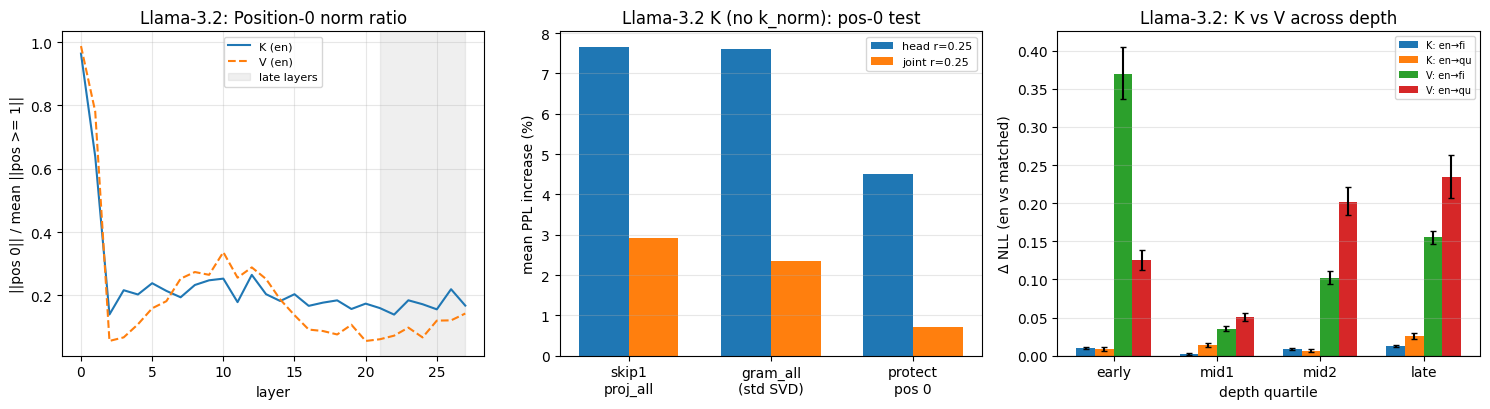

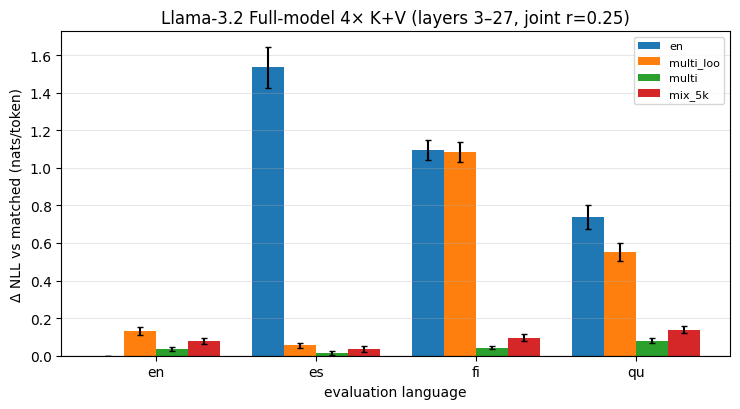

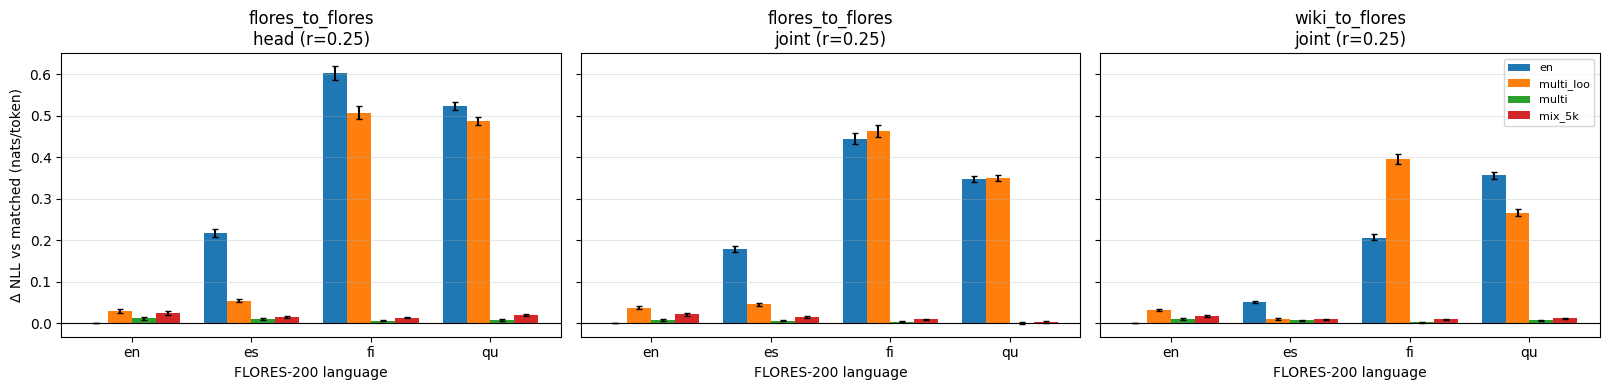

In [11]:
# Fig 1: Llama-3.2 Pos-0 sink profile + 3-way K treatment (no k_norm!)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
for kind, ls in (("K", "-"), ("V", "--")):
    s = l_df[l_df.kind == kind]
    ax.plot(s.layer, s.norm_ratio, ls, label=f"{kind} ({en_code})")
ax.axvspan(LATE[0], LATE[-1], color="gray", alpha=0.12, label="late layers")
ax.set_xlabel("layer"); ax.set_ylabel("||pos 0|| / mean ||pos >= 1||")
ax.set_title("Llama-3.2: Position-0 norm ratio"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[1]
treats = [t[0] for t in p2_treats]
t_lbl = ["skip1\nproj_all", "gram_all\n(std SVD)", "protect\npos 0"]
x = np.arange(len(treats)); w = 0.35
for idx, sc in enumerate(("head", "joint")):
    vals = [res2[(res2.treatment == t) & (res2.scope == sc)].ppl_increase_pct.mean() for t in treats]
    ax.bar(x + (idx - 0.5) * w, vals, w, label=f"{sc} r=0.25")
ax.set_xticks(x, t_lbl); ax.set_ylabel("mean PPL increase (%)")
ax.set_title("Llama-3.2 K (no k_norm): pos-0 test"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)

ax = axes[2]
band_order = ["early", "mid1", "mid2", "late"]
non_en = [l for l in p3_targets if l != en_code]
x = np.arange(len(band_order)); w = 0.18
k_idx = 0
for kind in ("K", "V"):
    for tgt in non_en:
        sub = res3[(res3.kind == kind) & (res3.target == tgt) & (res3.source == en_code)].set_index("band").reindex(band_order)
        y = sub.delta_vs_matched.values
        err = np.vstack([y - sub.ci_low.values, sub.ci_high.values - y])
        ax.bar(x + (k_idx - (2 * len(non_en) - 1) / 2) * w, y, w, yerr=err, capsize=2, label=f"{kind}: en→{tgt}")
        k_idx += 1
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x, band_order)
ax.set_xlabel("depth quartile"); ax.set_ylabel("Δ NLL (en vs matched)")
ax.set_title("Llama-3.2: K vs V across depth"); ax.legend(fontsize=7); ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig1_llama32_pos0_and_depth.png"), dpi=150)
plt.show()

# Fig 2: Full-model 4x K+V (layers 3..N-1)
show4 = [en_code, "multi_loo", "multi", "mix_5k"]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(len(p4_targets)); w = 0.8 / len(show4)
for k, s in enumerate(show4):
    sub = res4[res4.source == s].set_index("target").reindex(p4_targets)
    y = np.nan_to_num(sub.delta_vs_matched.values)
    err = np.nan_to_num(np.vstack([sub.delta_vs_matched.values - sub.ci_low.values, sub.ci_high.values - sub.delta_vs_matched.values]))
    ax.bar(x + (k - (len(show4) - 1) / 2) * w, y, w, yerr=err, capsize=2, label=s)
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x, p4_targets)
ax.set_xlabel("evaluation language"); ax.set_ylabel("Δ NLL vs matched (nats/token)")
ax.set_title(f"Llama-3.2 Full-model 4× K+V (layers {NO_SINK_LAYERS[0]}–{NO_SINK_LAYERS[-1]}, joint r=0.25)")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig2_llama32_full_model_kv.png"), dpi=150)
plt.show()

# Fig 3: FLORES-200 parallel control on Llama-3.2
show5 = [en_code, "multi_loo", "multi", "mix_5k"]
fig, axes = plt.subplots(1, len(p5_combos), figsize=(5.4 * len(p5_combos), 4.0), sharey=True, squeeze=False)
w = 0.8 / len(show5)
for ax, (regime, scope) in zip(axes[0], p5_combos):
    x = np.arange(len(LANGS))
    for k, s in enumerate(show5):
        sub = res5[(res5.regime == regime) & (res5.scope == scope) & (res5.source == s)].set_index("target").reindex(LANGS)
        y = np.nan_to_num(sub.delta_vs_matched.values)
        err = np.nan_to_num(np.vstack([sub.delta_vs_matched.values - sub.ci_low.values, sub.ci_high.values - sub.delta_vs_matched.values]))
        ax.bar(x + (k - (len(show5) - 1) / 2) * w, y, w, yerr=err, capsize=2, label=s)
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x, LANGS)
    ax.set_xlabel("FLORES-200 language"); ax.set_title(f"{regime}\n{scope} (r=0.25)")
    ax.grid(axis="y", alpha=0.3)
axes[0][0].set_ylabel("Δ NLL vs matched (nats/token)"); axes[0][-1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig3_llama32_flores_parallel.png"), dpi=150)
plt.show()

## 8. Reading guide (Qwen3-1.7B vs Llama-3.2-3B comparison)

1. **Part 2 (`part2_k_pos0_treatments.csv`):** Compare against Qwen3-1.7B (`+170–328%` standard SVD → `+1.2–2.0%` with `protect_pos0`). Because Llama-3.2 has **no `k_norm`**, this directly separates universal attention-sink fragility from QK-Norm amplification.
2. **Part 3 (`part3_depth_bands_kv.csv`):** Check whether `K` stays nearly language-agnostic across all four depth quartiles while `V` carries the cross-lingual penalty.
3. **Part 4 (`part4_full_model_kv.csv`):** Check whether full-model 4× `K+V` compression (`layers 3–27`, `joint`, `protect_pos0 = True`) reproduces both the severe English-calibration failure and the `mix_5k` (`w = 0.10`, ~5k tokens) recovery.
4. **Part 5 (`part5_flores_ppl.csv`):** Confirms on exact parallel FLORES-200 translations that cross-lingual calibration bias in `V` and the `5k`-token recipe hold across model families.